# Deep Learning-Based Recommendation Models

Pada sistem rekomendasi modern yang mengandalkan umpan balik implisit (*clicks*, *views*, *purchases*), model faktorisasi klasik seperti *Matrix Factorization* hanya mampu memetakan interaksi secara linear melalui perkalian titik (*dot product*). Pendekatan linear ini sering kali kurang optimal dalam menangkap pola preferensi pengguna yang kompleks dan berdimensi tinggi. Untuk mengatasi keterbatasan tersebut, arsitektur berbasis jaringan saraf tiruan (*neural network*) hadir sebagai solusi melalui **Neural Collaborative Filtering (NCF)**.


In [1]:
from copy import deepcopy
from pathlib import Path
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm
from urllib.request import urlretrieve
from zipfile import ZipFile

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn

sns.set_theme(style='whitegrid')

seed = 42
torch.manual_seed(seed)

device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [2]:
# Menentukan direktori utama dan lokasi file dataset MovieLens 100K.
pathMl = Path('../res/data/movielens')
pathZip = pathMl / 'ml-100k.zip'
pathRatings = pathMl / 'ml-100k' / 'u.data'
pathItem = pathMl / 'ml-100k' / 'u.item'

# Membuat direktori penyimpanan jika belum tersedia.
pathMl.mkdir(parents=True, exist_ok=True)

# Mengunduh dataset MovieLens 100K jika file ZIP belum tersedia.
if not pathZip.exists():
  urlretrieve(
    'https://files.grouplens.org/datasets/movielens/ml-100k.zip',
    pathZip,
  )

# Mengekstrak file rating pengguna jika belum tersedia.
if not pathRatings.exists():
  with ZipFile(pathZip) as archive:
    archive.extract('ml-100k/u.data', path=pathMl)

In [3]:
# Membaca dataset rating pengguna dan film dari MovieLens 100K.
df = pd.read_csv(
  pathRatings, 
  sep='\t', 
  header=None,
  usecols=[0, 1, 2],
  names=['userId', 'movieId', 'rating'],
)

# Menghapus rating netral (3) dari dataset.
df = df[df.rating != 3].copy()

# Mengonversi rating menjadi target biner: 0 untuk rating 1–2 dan 1 untuk rating 4–5.
df['target'] = (df.rating >= 4).astype(float)

# Mengonversi ID pengguna dan film menjadi indeks numerik mulai dari 0.
df.userId = df.userId.astype('category').cat.codes
df.movieId = df.movieId.astype('category').cat.codes

# Menghitung jumlah pengguna dan film unik untuk menentukan ukuran tabel embedding.
numUsers = df.userId.nunique()
numItems = df.movieId.nunique()

# Menampilkan informasi struktur, tipe data, dan jumlah nilai non-null pada dataset.
df.info()

<class 'pandas.DataFrame'>
Index: 72855 entries, 2 to 99998
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   userId   72855 non-null  int16  
 1   movieId  72855 non-null  int16  
 2   rating   72855 non-null  int64  
 3   target   72855 non-null  float64
dtypes: float64(1), int16(2), int64(1)
memory usage: 1.9 MB


In [4]:
# Membagi dataset menjadi 80% training dan 20% sementara dengan proporsi target tetap seimbang.
trainData, tempData = train_test_split(
  df,
  test_size=0.2,
  random_state=seed,
  stratify=df.target,
)

# Membagi dataset sementara menjadi 10% validation dan 10% testing dari total dataset.
valData, testData = train_test_split(
  tempData,
  test_size=0.5,
  random_state=seed,
  stratify=tempData.target,
)

# Mengatur ulang indeks setiap dataset agar dimulai dari 0 secara berurutan.
trainData = trainData.reset_index(drop=True)
valData = valData.reset_index(drop=True)
testData = testData.reset_index(drop=True)

# Menampilkan jumlah sampel pada masing-masing dataset.
print(f'Train: {len(trainData)}')
print(f'Validation: {len(valData)}')
print(f'Test: {len(testData)}')

Train: 58284
Validation: 7285
Test: 7286


In [5]:
def createDataLoader(
  df: pd.DataFrame,
  batchSize=256,
  shuffle=False,
):
  """
    Membuat DataLoader dari DataFrame untuk proses training, validation, dan testing.

    Args:
      df (pd.DataFrame): Dataset yang berisi ID pengguna, ID film, dan target.
      batchSize (int, optional): Jumlah sampel dalam setiap batch. Default 256.
      shuffle (bool, optional): Mengacak urutan sampel setiap epoch. Default False.

    Returns:
      DataLoader: DataLoader yang menghasilkan batch pengguna, film, dan target.
  """
  
  # Mengonversi kolom DataFrame menjadi tensor dengan tipe data yang sesuai.
  dataset = TensorDataset(
    torch.tensor(df.userId.to_numpy(), dtype=torch.long),
    torch.tensor(df.movieId.to_numpy(), dtype=torch.long),
    torch.tensor(df.target.to_numpy(), dtype=torch.float32),
  )
  
  # Membuat DataLoader untuk membagi dataset menjadi batch.
  return DataLoader(
    dataset,
    batch_size=batchSize,
    shuffle=shuffle,
  )

# Membuat DataLoader training dengan pengacakan sampel setiap epoch.
trainLoader = createDataLoader(trainData, shuffle=True)

# Membuat DataLoader validation tanpa pengacakan sampel.
valLoader = createDataLoader(valData)

# Membuat DataLoader testing tanpa pengacakan sampel.
testLoader = createDataLoader(testData)

## Neural Collaborative Filtering (NCF) dengan Neural Matrix Factorization (NeuMF)

**Neural Collaborative Filtering (NCF)** adalah pendekatan sistem rekomendasi berbasis *neural network* yang mempelajari pola interaksi antara pengguna (*user*) dan item tanpa membatasi hubungan keduanya pada perkalian titik (*dot product*) seperti *Matrix Factorization* (MF) klasik. Salah satu arsitektur NCF adalah **Neural Matrix Factorization (NeuMF)**, yang menggabungkan **Generalized Matrix Factorization (GMF)** untuk memodelkan interaksi laten secara elemen per elemen dan **Multi-Layer Perceptron (MLP)** untuk mempelajari pola interaksi nonlinier. Hasil kedua komponen digabungkan untuk menghasilkan satu nilai prediksi bagi setiap pasangan pengguna–item.

Pada implementasi `class NeuMF(nn.Module)`, model menerima indeks pengguna dan item, lalu menghasilkan **logit**. Probabilitas diperoleh dengan menerapkan fungsi *sigmoid* pada logit saat inferensi; selama pelatihan, `nn.BCEWithLogitsLoss()` menangani fungsi sigmoid secara internal.

> **Catatan:** Penggunaan **GPU direkomendasikan** untuk mempercepat proses pelatihan NeuMF, khususnya ketika jumlah data, dimensi embedding, atau jumlah eksperimen meningkat. Pelatihan tetap dapat dilakukan menggunakan **CPU**, tetapi biasanya membutuhkan waktu lebih lama. Jika komputer tidak memiliki GPU yang kompatibel, alternatifnya adalah menjalankan notebook melalui **Google Colab** atau **Kaggle Notebooks** dengan akselerator GPU, sesuai ketersediaan dan batas penggunaan masing-masing layanan.

---

## 1. Persamaan Model & Pemetaan Variabel Kode

Model NeuMF menggabungkan hasil GMF dan MLP menggunakan persamaan berikut:

$$
\begin{aligned}
\mathbf{g}_{ui} &= \mathbf{p}_{u}^{G} \odot \mathbf{q}_{i}^{G} \\
\mathbf{m}_{ui}^{(0)} &= [\mathbf{p}_{u}^{M};\mathbf{q}_{i}^{M}] \\
\mathbf{m}_{ui}^{(\ell)} &= \operatorname{Dropout}_{0.2}\!\left(\operatorname{ReLU}\!\left(\mathbf{W}_{\ell}\mathbf{m}_{ui}^{(\ell-1)}+\mathbf{b}_{\ell}\right)\right) \\
\mathbf{c}_{ui} &= [\mathbf{g}_{ui};\mathbf{m}_{ui}^{(L)}] \\
s_{ui} &= \mathbf{h}^{T}\mathbf{c}_{ui}+b \\
\hat{y}_{ui} &= \sigma(s_{ui}) = \frac{1}{1+e^{-s_{ui}}}
\end{aligned}
$$

Pada mode evaluasi (`model.eval()`), *dropout* dinonaktifkan sehingga hasil setiap hidden layer hanya melalui transformasi linear dan ReLU. Metode `forward()` mengembalikan $s_{ui}$ (**logit**), bukan $\hat{y}_{ui}$ (**probabilitas**).

### Notasi Umum: Pengguna, Item, dan Embedding

| Simbol Matematis | Variabel dalam Kode  | Penjelasan                                                          |
| :--------------- | :------------------- | :------------------------------------------------------------------ |
| $u$            | `userIds`          | Indeks pengguna yang akan diprediksi.                               |
| $i$            | `itemIds`          | Indeks item atau film yang akan diprediksi.                         |
| $U$            | `numUsers`         | Jumlah pengguna yang menentukan banyaknya baris embedding pengguna. |
| $I$            | `numItems`         | Jumlah item yang menentukan banyaknya baris embedding item.         |
| $d$            | `embeddingDim`     | Dimensi vektor laten pengguna dan item pada setiap komponen.        |
| $L$            | `len(hiddenUnits)` | Jumlah hidden layer pada jaringan MLP.                              |

### Notasi Generalized Matrix Factorization (GMF)

Komponen GMF memodelkan interaksi menggunakan perkalian elemen per elemen (*element-wise product*):

$$
\mathbf{g}_{ui}=\mathbf{p}_{u}^{G}\odot\mathbf{q}_{i}^{G}
$$

| Simbol Matematis       | Variabel dalam Kode                      | Penjelasan                                                |
| :--------------------- | :--------------------------------------- | :-------------------------------------------------------- |
| $\mathbf{p}_{u}^{G}$ | `gmfUser = self.gmfUserEmbed(userIds)` | Vektor embedding pengguna GMF berukuran $d$.            |
| $\mathbf{q}_{i}^{G}$ | `gmfItem = self.gmfItemEmbed(itemIds)` | Vektor embedding item GMF berukuran $d$.                |
| $\odot$              | `gmfUser * gmfItem`                    | Perkalian elemen pada posisi yang sama dari kedua vektor. |
| $\mathbf{g}_{ui}$    | `gmf`                                  | Representasi interaksi GMF berukuran $d$.               |

### Notasi Multi-Layer Perceptron (MLP)

Komponen MLP menggabungkan embedding pengguna dan item, kemudian memprosesnya melalui beberapa hidden layer:

$$
\mathbf{m}_{ui}^{(0)}=[\mathbf{p}_{u}^{M};\mathbf{q}_{i}^{M}]
$$

$$
\mathbf{m}_{ui}^{(\ell)}=\operatorname{Dropout}_{0.2}\left(\operatorname{ReLU}(\mathbf{W}_{\ell}\mathbf{m}_{ui}^{(\ell-1)}+\mathbf{b}_{\ell})\right)
$$

| Simbol Matematis                 | Variabel dalam Kode                      | Penjelasan                                                                            |
| :------------------------------- | :--------------------------------------- | :------------------------------------------------------------------------------------ |
| $\mathbf{p}_{u}^{M}$           | `mlpUser = self.mlpUserEmbed(userIds)` | Vektor embedding pengguna MLP yang terpisah dari GMF.                                 |
| $\mathbf{q}_{i}^{M}$           | `mlpItem = self.mlpItemEmbed(itemIds)` | Vektor embedding item MLP yang terpisah dari GMF.                                     |
| $[\,;\,]$                      | `torch.cat(..., dim=-1)`               | Operasi konkatenasi dua vektor pada dimensi fitur.                                    |
| $\mathbf{m}_{ui}^{(0)}$        | `mlpCombined`                          | Vektor masukan MLP berukuran $2d$.                                                  |
| $\mathbf{W}_{\ell}$            | `nn.Linear(...).weight`                | Matriks bobot pada hidden layer ke-$\ell$.                                          |
| $\mathbf{b}_{\ell}$            | `nn.Linear(...).bias`                  | Vektor bias pada hidden layer ke-$\ell$.                                            |
| $\operatorname{ReLU}$          | `nn.ReLU()`                            | Fungsi aktivasi nonlinier $\max(0,x)$.                                              |
| $\operatorname{Dropout}_{0.2}$ | `nn.Dropout(p=0.2)`                    | Menonaktifkan sebagian aktivasi secara acak saat training; tidak aktif saat evaluasi. |
| $\mathbf{m}_{ui}^{(L)}$        | `mlp = self.mlpNetwork(mlpCombined)`   | Representasi akhir MLP dengan dimensi `hiddenUnits[-1]`.                            |

### Notasi Neural Matrix Factorization (NeuMF)

Hasil GMF dan MLP digabungkan, kemudian dipetakan menjadi satu logit melalui layer linear:

$$
s_{ui}=\mathbf{h}^{T}[\mathbf{g}_{ui};\mathbf{m}_{ui}^{(L)}]+b
$$

$$
\hat{y}_{ui}=\sigma(s_{ui})
$$

| Simbol Matematis    | Variabel dalam Kode                       | Penjelasan                                                           |
| :------------------ | :---------------------------------------- | :------------------------------------------------------------------- |
| $\mathbf{c}_{ui}$ | `neumf = torch.cat([gmf, mlp], dim=-1)` | Representasi gabungan dengan dimensi $d+\texttt{hiddenUnits[-1]}$. |
| $\mathbf{h}$      | `self.output.weight`                    | Bobot linear yang menggabungkan seluruh fitur GMF dan MLP.           |
| $b$               | `self.output.bias`                      | Bias pada layer output NeuMF.                                        |
| $s_{ui}$          | `logits = self.output(neumf)`           | Skor prediksi mentah sebelum sigmoid.                                |
| $\sigma$          | `torch.sigmoid(logits)`                 | Fungsi yang mengubah logit menjadi probabilitas.                     |
| $\hat{y}_{ui}$    | `probabilities` (saat evaluasi)         | Probabilitas target positif untuk pasangan pengguna–item.           |

Dengan konfigurasi `embeddingDim=16` dan `hiddenUnits=(32, 16, 8)`, GMF menghasilkan **16 fitur**, MLP menghasilkan **8 fitur**, dan layer output menerima **24 fitur** untuk menghasilkan **1 logit**.

---

## 2. Cara Kerja Metode `forward(self, userIds, itemIds)`

Metode `forward()` menghitung interaksi pengguna–item melalui dua jalur paralel, yaitu GMF dan MLP. Seluruh operasi dapat diproses sekaligus untuk satu *batch* tanpa melakukan perulangan Python atas setiap pasangan pengguna–item.

Alur komputasi di dalam `forward(userIds, itemIds)`:

1. **`gmfUser` & `gmfItem`:** Mengambil embedding pengguna dan item dari `self.gmfUserEmbed` serta `self.gmfItemEmbed` dengan dimensi masing-masing $d$.
2. **`gmf`:** Menghitung $\mathbf{p}_{u}^{G}\odot\mathbf{q}_{i}^{G}$ menggunakan `gmfUser * gmfItem` untuk menghasilkan representasi GMF.
3. **`mlpUser` & `mlpItem`:** Mengambil embedding pengguna dan item dari tabel MLP yang parameternya **berbeda** dari embedding GMF.
4. **`mlpCombined`:** Menggabungkan kedua embedding MLP menggunakan `torch.cat([mlpUser, mlpItem], dim=-1)` sehingga dimensinya menjadi $2d$.
5. **`mlp`:** Memproses vektor gabungan melalui `self.mlpNetwork`, yang berisi urutan `nn.Linear`, `nn.ReLU`, dan `nn.Dropout(p=0.2)` pada setiap hidden layer.
6. **`neumf`:** Menggabungkan hasil GMF dan MLP menggunakan `torch.cat([gmf, mlp], dim=-1)` untuk membentuk representasi akhir berukuran $d+\texttt{hiddenUnits[-1]}$.
7. **`logits`:** Menghitung skor menggunakan `self.output(neumf)` dan menghapus dimensi terakhir dengan `squeeze(-1)` agar bentuk output menjadi `(batchSize,)`.

Konfigurasi `(32, 16, 8)` pada `hiddenUnits` berarti MLP memproses dimensi **32 → 32 → 16 → 8**, karena input awalnya merupakan konkatenasi dua embedding berdimensi 16. Penggunaan `nn.Dropout(p=0.2)` membantu regularisasi selama pelatihan, sedangkan `model.eval()` menonaktifkannya ketika validasi dan pengujian.

---

## 3. Proses Pelatihan dengan Adam, Binary Cross-Entropy, dan Early Stopping

Metode `forward()` hanya mendefinisikan proses prediksi. Pelatihan dilakukan melalui fungsi `train(model)` di luar kelas menggunakan **Adam** untuk memperbarui parameter embedding, bobot MLP, dan layer output berdasarkan *Binary Cross-Entropy* (BCE).

### Tujuan Pelatihan (Fungsi *Loss*)

Untuk setiap pasangan pengguna–item, model menghasilkan logit $s_{ui}$ dan target biner $y_{ui}\in\{0,1\}$. Fungsi `nn.BCEWithLogitsLoss()` menghitung:

$$
\ell(s_{ui},y_{ui})=-\left[y_{ui}\log\sigma(s_{ui})+(1-y_{ui})\log(1-\sigma(s_{ui}))\right]
$$

Untuk satu *batch* berisi $B$ sampel, loss rata-ratanya adalah:

$$
\mathcal{L}_{\mathrm{BCE}}=\frac{1}{B}\sum_{(u,i)\in\mathcal{B}}\ell(s_{ui},y_{ui})
$$

* **Target Positif ($y_{ui}=1$):** Pada pemrosesan dataset MovieLens yang digunakan, rating 4–5 dianggap sebagai interaksi yang disukai.
* **Target Negatif ($y_{ui}=0$):** Rating 1–2 dianggap sebagai interaksi yang tidak disukai, sedangkan rating 3 dikeluarkan sebagai nilai netral.
* **`BCEWithLogitsLoss`:** Menggabungkan sigmoid dan BCE secara numerik stabil. Oleh karena itu, `forward()` harus mengembalikan **logit**, bukan probabilitas sigmoid.
* **`weightDecay`:** Parameter `weight_decay` pada `torch.optim.Adam` memberikan regularisasi terhadap bobot selama pembaruan optimizer untuk membantu mengurangi *overfitting*.

### Langkah Pembaruan Parameter (Per Satu Batch)

Setiap batch dari `trainLoader` diproses melalui langkah berikut:

1. **`model.train()`:** Mengaktifkan mode pelatihan sehingga dropout bekerja pada hidden layer MLP.
2. **`userBatch`, `itemBatch`, `targetBatch`:** Memindahkan indeks pengguna, indeks item, dan target ke perangkat komputasi menggunakan `.to(device)`.
3. **`optimizer.zero_grad()`:** Mengosongkan gradien sebelum melakukan pembaruan parameter berikutnya.
4. **`logits` & `loss`:** Menjalankan `model(userBatch, itemBatch)` dan menghitung `criterion(logits, targetBatch)`.
5. **`loss.backward()`:** Menghitung gradien seluruh parameter yang berkontribusi terhadap prediksi melalui *backpropagation*.
6. **`optimizer.step()`:** Memperbarui embedding, bobot linear, dan bias menggunakan algoritma Adam.
7. **`trainLoss`:** Menjumlahkan `loss.item() * batchSize`, lalu membaginya dengan jumlah sampel training untuk memperoleh rata-rata loss tiap epoch.

### Validasi dan Early Stopping

Setelah setiap epoch, model dievaluasi menggunakan `model.eval()` dan `torch.no_grad()` untuk menghitung `valLoss` tanpa pembaruan parameter. Jika `valLoss` lebih rendah daripada `bestValLoss`, bobot model disimpan melalui `deepcopy(model.state_dict())` dan penghitung `patienceCounter` diatur kembali ke nol.

Jika validation loss tidak membaik selama **3 epoch berturut-turut** (`patience=3`), pelatihan dihentikan. Bobot dari epoch dengan validation loss terendah dipulihkan menggunakan `model.load_state_dict(bestModelState)`, sehingga evaluasi akhir dilakukan terhadap checkpoint terbaik, bukan sekadar epoch terakhir.

---

## 4. Contoh Hitungan Sederhana

Misalkan model memprediksi apakah **User 1** menyukai **Movie A**. Untuk mempermudah perhitungan, digunakan dimensi embedding $d=2$ dan satu hidden layer MLP dengan 2 neuron (`hiddenUnits=(2,)`). Contoh ini menggunakan bobot ilustratif dan dilakukan dalam **mode evaluasi**, sehingga dropout tidak aktif.

* **Embedding GMF:**

  * $\mathbf{p}_{u}^{G}=[0.8,\ 0.3]$
  * $\mathbf{q}_{i}^{G}=[0.9,\ 0.4]$
* **Embedding MLP:**

  * $\mathbf{p}_{u}^{M}=[0.2,\ 0.5]$
  * $\mathbf{q}_{i}^{M}=[0.6,\ 0.4]$
* **Parameter hidden layer MLP:**

  $$
  \mathbf{W}_{1}=\begin{bmatrix}0.5&0.2&0.1&0.4\\-0.3&0.6&0.2&0.1\end{bmatrix},\qquad\mathbf{b}_{1}=\begin{bmatrix}0.1\\-0.2\end{bmatrix}
  $$
* **Parameter output NeuMF:** $\mathbf{h}=[0.5,\ -0.4,\ 0.7,\ 0.3]$, $b=-0.1$.

**Langkah Perhitungan:**

   $$
      \begin{aligned}
      \mathbf{m}_{ui}^{(0)} &= [\mathbf{p}_{u}^{M};\mathbf{q}_{i}^{M}] \\
      \mathbf{m}_{ui}^{(\ell)} &= \operatorname{Dropout}_{0.2}\!\left(\operatorname{ReLU}\!\left(\mathbf{W}_{\ell}\mathbf{m}_{ui}^{(\ell-1)}+\mathbf{b}_{\ell}\right)\right) \\
      \mathbf{c}_{ui} &= [\mathbf{g}_{ui};\mathbf{m}_{ui}^{(L)}] \\
      s_{ui} &= \mathbf{h}^{T}\mathbf{c}_{ui}+b \\
      \hat{y}_{ui} &= \sigma(s_{ui}) = \frac{1}{1+e^{-s_{ui}}}
      \end{aligned}
   $$

1. **`gmf` (Interaksi GMF):**

   $$
   \mathbf{g}_{ui}=[0.8\times0.9,\ 0.3\times0.4]=[0.72,\ 0.12]
   $$
2. **`mlpCombined` (Input MLP):**

   $$
   \mathbf{m}_{ui}^{(0)}=[0.2,\ 0.5,\ 0.6,\ 0.4]
   $$
3. **`mlp` (Hidden Layer):**

   $$
   \mathbf{W}_{1}\mathbf{m}_{ui}^{(0)}+\mathbf{b}_{1}=[0.52,\ 0.20]
   $$

   $$
   \mathbf{m}_{ui}^{(1)}=\operatorname{ReLU}([0.52,\ 0.20])=[0.52,\ 0.20]
   $$
4. **`neumf` (Konkatenasi GMF dan MLP):**

   $$
   \mathbf{c}_{ui}=[0.72,\ 0.12,\ 0.52,\ 0.20]
   $$
5. **`logits` (Skor Mentah):**

   $$
   s_{ui}=(0.5\times0.72)+(-0.4\times0.12)+(0.7\times0.52)+(0.3\times0.20)-0.1=0.636
   $$
6. **`sigmoid` (Probabilitas Prediksi):**

   $$
   \hat{y}_{ui}=\sigma(0.636)=\frac{1}{1+e^{-0.636}}\approx\mathbf{0.6538}
   $$

Dengan ambang klasifikasi **0.5**, probabilitas $0.6538$ menghasilkan label prediksi **1 (positif)**. Nilai ini merupakan contoh ilustratif, bukan hasil pelatihan model MovieLens yang sebenarnya.

---

## 5. Aplikasi Neural Collaborative Filtering (NeuMF)

NeuMF dapat digunakan pada berbagai sistem rekomendasi yang merepresentasikan interaksi melalui pasangan identitas pengguna dan item:

1. **Rekomendasi Film:** Memperkirakan kemungkinan pengguna menyukai suatu film berdasarkan histori rating pengguna–film. Pada konfigurasi MovieLens ini, model membedakan rating **1–2 (negatif)** dan **4–5 (positif)**.
2. **Rekomendasi Produk E-Commerce:** Mempelajari kecenderungan interaksi pengguna–produk berdasarkan label biner, seperti pembelian atau tindakan tertentu, setelah definisi target dan proses sampling disesuaikan.
3. **Rekomendasi Konten Digital:** Memperkirakan ketertarikan pengguna terhadap video, musik, atau artikel dengan mempelajari pola interaksi sebelumnya.
4. **Pemeringkatan Kandidat Item:** Menghitung skor probabilitas untuk beberapa item yang sudah memiliki embedding terlatih, kemudian mengurutkannya sebagai kandidat rekomendasi bagi pengguna tertentu.

Pada implementasi ini, `forward()` hanya menerima **ID pengguna dan ID item**. Informasi tambahan seperti judul, genre, atau deskripsi film **tidak digunakan secara langsung**, sehingga model belum menangani pengguna atau item baru (*cold-start*) tanpa perubahan arsitektur atau strategi tambahan.

---

## 6. Kelebihan dan Kekurangan Neural Collaborative Filtering (NeuMF)

| Kelebihan (*Pros*)                                                                                                                                                             | Kekurangan (*Cons*)                                                                                                                                                                                             |
| :------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | :---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Memodelkan Pola Nonlinier:** MLP mempelajari hubungan pengguna–item yang lebih fleksibel dibanding pembatasan pada perkalian titik MF klasik.                           | **Rentan Overfitting:** Tabel embedding terpisah dan jaringan MLP memiliki banyak parameter, terutama pada dataset interaksi yang relatif kecil.                                                            |
| **Menggabungkan Dua Pendekatan:** GMF menangkap interaksi laten elemen per elemen, sedangkan MLP membentuk representasi interaksi yang lebih kompleks.                     | **Membutuhkan Tuning Hiperparameter:** Dimensi embedding, ukuran hidden layer, dropout, weight decay, dan early stopping memengaruhi generalisasi.                                                          |
| **Mendukung Pelatihan Berbasis Batch:** Operasi embedding dan neural network dapat dihitung secara paralel melalui PyTorch dan diakselerasi menggunakan GPU.               | **Masalah Cold-Start:** Pengguna atau item yang tidak pernah muncul saat pelatihan tidak memiliki representasi embedding yang telah dipelajari.                                                             |
| **Fleksibel untuk Prediksi Biner:** Output logit dapat dilatih dengan `BCEWithLogitsLoss` dan diubah menjadi probabilitas untuk klasifikasi atau pemeringkatan kandidat. | **Terbatas pada Informasi ID:** Kelas ini belum memanfaatkan fitur konten seperti genre, teks, atau metadata; selain itu, prediksi rating positif tidak otomatis setara dengan prediksi interaksi implisit. |

In [6]:
class NeuMF(nn.Module):
  """
    Implementasi model Neural Matrix Factorization (NeuMF) dengan kombinasi Generalized Matrix Factorization (GMF) dan Multi-Layer Perceptron (MLP).

    Persamaan Model:
    y_hat_ui = sigmoid(h^T * [p_u^G ⊙ q_i^G ; MLP([p_u^M ; q_i^M])] + b)
  """
  
  def __init__(
    self,
    numUsers: int,
    numItems: int,
    embeddingDim=16,
    hiddenUnits=(32, 16, 8),
  ):
    """
      Inisialisasi hiperparameter dan komponen model Neural Matrix Factorization (NeuMF).

      Args:
        numUsers (int): Merepresentasikan jumlah total pengguna, yaitu jumlah baris pada tabel embedding pengguna.
        numItems (int): Merepresentasikan jumlah total item, yaitu jumlah baris pada tabel embedding item.
        embeddingDim (int, optional): Merepresentasikan simbol d, yaitu panjang dimensi vektor embedding untuk setiap pengguna dan item. Default 16.
        hiddenUnits (tuple[int, ...], optional): Merepresentasikan jumlah neuron pada setiap hidden layer MLP secara berurutan. Setiap elemen menentukan jumlah output fitur dari layer tersebut. Default (32, 16, 8).
    """
    
    super().__init__()
    
    # Inisialisasi tabel embedding pengguna dan item untuk komponen GMF.
    # Setiap pengguna dan item direpresentasikan oleh vektor laten berdimensi embeddingDim.
    self.gmfUserEmbed = nn.Embedding(numUsers, embeddingDim)
    self.gmfItemEmbed = nn.Embedding(numItems, embeddingDim)
    
    # Inisialisasi tabel embedding pengguna dan item untuk komponen MLP.
    # Embedding GMF dan MLP menggunakan parameter yang terpisah.
    self.mlpUserEmbed = nn.Embedding(numUsers, embeddingDim)
    self.mlpItemEmbed = nn.Embedding(numItems, embeddingDim)
    
    # Menyiapkan daftar layer yang akan disusun menjadi jaringan MLP.
    mlpLayers: list[nn.Module] = []
    
    # Menentukan jumlah fitur input layer pertama MLP.
    # Input berasal dari konkatenasi embedding pengguna dan item.
    inFeatures = embeddingDim * 2
    
    # Membangun hidden layer MLP berdasarkan jumlah neuron yang ditentukan.
    for unit in hiddenUnits:
      # Menambahkan layer linear untuk transformasi fitur.
      # nn.Linear mengubah jumlah fitur dari inFeatures menjadi unit.
      # ReLU digunakan sebagai fungsi aktivasi setelah transformasi linear.
      mlpLayers += [
        nn.Linear(inFeatures, unit),
        nn.ReLU(),
        nn.Dropout(p=0.2),
      ]
      
      # Memperbarui jumlah fitur input untuk layer berikutnya.
      # Output layer saat ini menjadi input layer selanjutnya.
      inFeatures = unit
    
    # Menggabungkan seluruh layer menjadi satu jaringan MLP berurutan.
    self.mlpNetwork = nn.Sequential(*mlpLayers)
    
    # Inisialisasi layer output NeuMF.
    # Jumlah input merupakan gabungan dimensi output GMF dan MLP.
    # GMF menghasilkan embeddingDim fitur, sedangkan MLP menghasilkan hiddenUnits[-1] fitur.
    # Layer menghasilkan satu nilai logit untuk setiap pasangan pengguna dan item.
    self.output = nn.Linear(embeddingDim + hiddenUnits[-1], 1)
    
    # Menginisialisasi bobot embedding dengan distribusi normal.
    self._initializeWeights()
    
  def _initializeWeights(self):
    """
      Inisialisasi bobot embedding pengguna dan item pada komponen GMF dan MLP menggunakan distribusi normal.

      Setiap bobot diinisialisasi dengan nilai rata-rata 0 dan standar deviasi 0.01 untuk memberikan nilai awal acak dengan magnitudo kecil sebelum proses training.
    """
    
    # Inisialisasi bobot embedding pengguna dan item pada komponen GMF.
    # Setiap bobot diambil dari distribusi normal dengan rata-rata 0 dan standar deviasi 0.01.
    nn.init.normal_(self.gmfUserEmbed.weight, std=0.01)
    nn.init.normal_(self.gmfItemEmbed.weight, std=0.01)
    
    # Inisialisasi bobot embedding pengguna dan item pada komponen MLP.
    # Setiap bobot diambil dari distribusi normal dengan rata-rata 0 dan standar deviasi 0.01.
    nn.init.normal_(self.mlpUserEmbed.weight, std=0.01)
    nn.init.normal_(self.mlpItemEmbed.weight, std=0.01)
    
  def forward(
    self,
    userIds: torch.Tensor,
    itemIds: torch.Tensor,
  ) -> torch.Tensor:
    """
      Melakukan proses forward pass model Neural Matrix Factorization (NeuMF) untuk menghasilkan prediksi interaksi antara pengguna dan item.

      Args:
        userIds (torch.Tensor): Merepresentasikan 1D pengguna yang digunakan untuk mengambil vektor embedding dari tabel embedding GMF dan MLP.
        itemIds (torch.Tensor): Merepresentasikan 1D item yang digunakan untuk mengambil vektor embedding dari tabel embedding GMF dan MLP.

      Returns:
        torch.Tensor: Menghasilkan nilai logit untuk setiap pasangan pengguna dan item. Nilai logit merupakan hasil kombinasi komponen GMF dan MLP sebelum diterapkan fungsi aktivasi sigmoid.
    """
    
    # Mengambil vektor embedding pengguna dan item dari komponen GMF.
    gmfUser = self.gmfUserEmbed(userIds)
    gmfItem = self.gmfItemEmbed(itemIds)
    
    # Menghitung interaksi antara embedding pengguna dan item menggunakan perkalian elemen per elemen.
    # Hasilnya merupakan representasi interaksi pengguna dan item pada komponen GMF.
    gmf = gmfUser * gmfItem
    
    # Mengambil vektor embedding pengguna dan item dari komponen MLP.
    mlpUser = self.mlpUserEmbed(userIds)
    mlpItem = self.mlpItemEmbed(itemIds)
    
    # Menggabungkan embedding pengguna dan item pada dimensi fitur sebagai input jaringan MLP.
    mlpCombined = torch.cat(
      [mlpUser, mlpItem],
      dim=-1,
    )
    
    # Memproses hasil konkatenasi embedding melalui jaringan MLP.
    mlp = self.mlpNetwork(mlpCombined)
    
    # Menggabungkan representasi interaksi dari GMF dan MLP pada dimensi fitur.
    neumf = torch.cat(
      [gmf, mlp],
      dim=-1,
    )
    
    # Menghitung nilai logit menggunakan layer output NeuMF.
    # Nilai logit merupakan hasil transformasi linear dari representasi gabungan GMF dan MLP.
    logits = self.output(neumf)
    
    # Menghilangkan dimensi terakhir yang berukuran 1 agar output berbentuk satu nilai logit per pasangan pengguna dan item.
    return logits.squeeze(-1)

In [7]:
# Menginisialisasi model NeuMF dengan konfigurasi embedding dan hidden layer MLP.
model = NeuMF(
  numUsers=numUsers,
  numItems=numItems,
  embeddingDim=16,
  hiddenUnits=[32, 16, 8],
).to(device)

# Menggunakan Binary Cross-Entropy Loss untuk klasifikasi biner berbasis logit.
criterion = nn.BCEWithLogitsLoss()

def train(
  model,
  epochs=20, 
  lr=1e-3,
  patience=3,
  weightDecay=1e-5,
) -> tuple[int, float, list[float], list[float]]:
  """
    Melatih model NeuMF dengan optimasi Adam, validasi, dan early stopping.

    Args:
      model (nn.Module): Model NeuMF yang akan dilatih.
      epochs (int, optional): Jumlah maksimum epoch pelatihan. Default 20.
      lr (float, optional): Learning rate optimizer Adam. Default 1e-3.
      patience (int, optional): Jumlah epoch tanpa perbaikan sebelum early stopping. Default 3.
      weightDecay (float, optional): Koefisien regularisasi weight decay. Default 1e-5.

    Returns:
      tuple[int, float, list[float], list[float]]:
        Epoch terbaik, validation loss terbaik, riwayat training loss,
        dan riwayat validation loss.
  """
  
  # Menginisialisasi optimizer Adam dengan regularisasi weight decay.
  optimizer = torch.optim.Adam(
    model.parameters(), 
    lr=lr,
    weight_decay=weightDecay,
  )

  # Menyiapkan variabel untuk menyimpan model terbaik dan memantau early stopping.
  bestEpoch = 0
  bestModelState = None
  bestValLoss = float('inf')
  patienceCounter = 0

  # Membuat progress bar untuk memantau proses pelatihan setiap epoch.
  progressBar = tqdm(
    range(epochs),
    desc='Training',
    unit='epoch',
  )

  # Menyimpan riwayat loss untuk visualisasi dan evaluasi.
  trainLossHistory = []
  valLossHistory = []
  
  for epoch in range(epochs):
    # Mengaktifkan mode training dan menginisialisasi akumulasi training loss.
    model.train()
    trainLoss = 0.0
    
    for batch in trainLoader:
      # Memindahkan seluruh tensor batch ke perangkat komputasi.
      userBatch, itemBatch, targetBatch = (
        tensor.to(device, non_blocking=True)
        for tensor in batch
      )
      
      # Mengosongkan gradien dari iterasi sebelumnya.
      optimizer.zero_grad()
      
      # Menghitung prediksi logit dan training loss.
      logits = model(userBatch, itemBatch)
      loss = criterion(logits, targetBatch)
      
      # Menghitung gradien dan memperbarui parameter model.
      loss.backward()
      optimizer.step()
      
      # Mengakumulasi loss berdasarkan jumlah sampel dalam batch.
      trainLoss += loss.item() * userBatch.size(0)
    
    # Menghitung rata-rata training loss dan menyimpan riwayatnya.
    trainLoss /= len(trainLoader.dataset)
    trainLossHistory.append(trainLoss)   
    
    # Mengaktifkan mode evaluasi dan menginisialisasi validation loss.
    model.eval()
    valLoss = 0.0
    
    # Melakukan validasi tanpa menghitung gradien.
    with torch.no_grad():
      for batch in valLoader:
        # Memindahkan seluruh tensor batch ke perangkat komputasi.
        userBatch, itemBatch, targetBatch = (
          tensor.to(device, non_blocking=True)
          for tensor in batch
        )
        
        # Menghitung prediksi logit dan validation loss.
        logits = model(userBatch, itemBatch)
        loss = criterion(logits, targetBatch)
        
        # Mengakumulasi loss berdasarkan jumlah sampel dalam batch.
        valLoss += loss.item() * userBatch.size(0)
    
    # Menghitung rata-rata validation loss dan menyimpan riwayatnya.
    valLoss /= len(valLoader.dataset)
    valLossHistory.append(valLoss)
    
    # Menyimpan parameter model jika validation loss mencapai nilai terbaik.
    if valLoss < bestValLoss:
      bestValLoss = valLoss
      bestEpoch = epoch + 1
      bestModelState = deepcopy(model.state_dict())
      patienceCounter = 0
    else:
      # Menambah penghitung jika validation loss tidak membaik.
      patienceCounter += 1
    
    # Memperbarui informasi loss dan early stopping pada progress bar.
    progressBar.set_postfix(
      trainLoss=f'{trainLoss:.4f}',
      valLoss=f'{valLoss:.4f}',
      bestValLoss=f'{bestValLoss:.4f}',
      patience=f'{patienceCounter}/{patience}',
    )
    
    # Memperbarui jumlah epoch yang telah selesai.
    progressBar.update(1)
    
    # Menghentikan pelatihan jika batas patience tercapai.
    if patienceCounter >= patience:
      tqdm.write(f'Early stopping at epoch {epoch + 1}')
      break
  
  # Menutup progress bar setelah pelatihan selesai.
  progressBar.close()
  
  # Mengembalikan parameter model dari epoch dengan validation loss terbaik.
  if bestModelState is not None:
    model.load_state_dict(bestModelState)
  
  # Menampilkan hasil epoch dan validation loss terbaik.
  print(f'Best Epoch: {bestEpoch}')
  print(f'Best Val Loss: {bestValLoss:.4f}')
  
  # Mengembalikan informasi dan riwayat loss untuk evaluasi.
  return bestEpoch, bestValLoss, trainLossHistory, valLossHistory

# Menjalankan pelatihan dan menyimpan hasil evaluasi model.
bestEpoch, bestValLoss, trainLossHistory, valLossHistory = train(model)

Training:   0%|          | 0/20 [00:00<?, ?epoch/s]

Early stopping at epoch 8
Best Epoch: 5
Best Val Loss: 0.3693


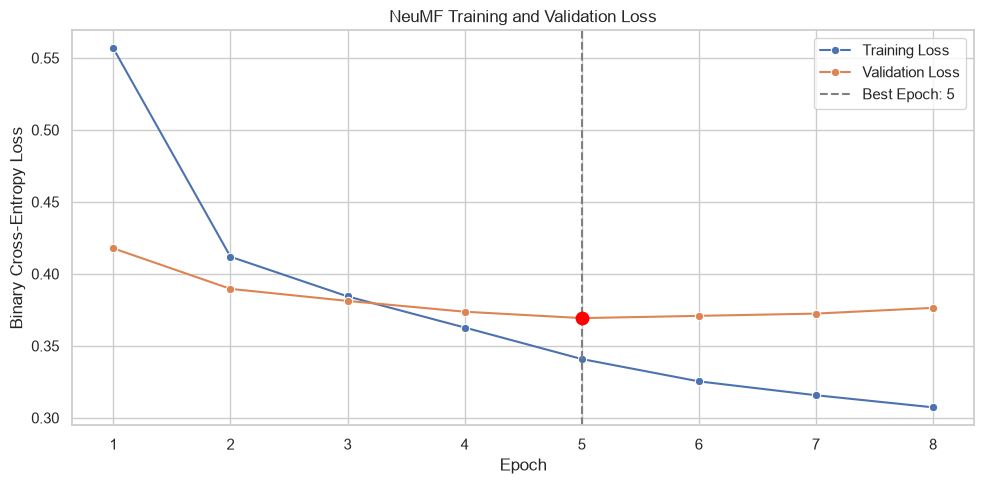

In [8]:
# Menentukan nomor epoch berdasarkan jumlah riwayat training loss.
epochNumbers = range(1, len(trainLossHistory) + 1)

# Membuat figure dan axes untuk visualisasi loss.
fig, ax = plt.subplots(figsize=(10, 5))

# Menampilkan perubahan training loss pada setiap epoch.
sns.lineplot(
  x=epochNumbers,
  y=trainLossHistory,
  marker='o',
  label='Training Loss',
  ax=ax,
)

# Menampilkan perubahan validation loss pada setiap epoch.
sns.lineplot(
  x=epochNumbers,
  y=valLossHistory,
  marker='o',
  label='Validation Loss',
  ax=ax,
)

# Menandai epoch terbaik dengan garis vertikal putus-putus.
ax.axvline(
  x=bestEpoch,
  color='gray',
  linestyle='--',
  label=f'Best Epoch: {bestEpoch}',
)

# Menandai titik validation loss terendah pada epoch terbaik.
ax.scatter(
  bestEpoch,
  bestValLoss,
  color='red',
  s=80,
  zorder=5,
)

# Mengatur judul grafik dan label masing-masing sumbu.
ax.set(
  title='NeuMF Training and Validation Loss',
  xlabel='Epoch',
  ylabel='Binary Cross-Entropy Loss',
)

# Menampilkan legenda dan menyesuaikan tata letak grafik.
ax.legend()
plt.tight_layout()
plt.show()

In [9]:
# Mengaktifkan mode evaluasi untuk menonaktifkan dropout.
model.eval()

# Menginisialisasi akumulasi test loss serta penyimpanan hasil prediksi dan target.
testLoss = 0.0
testPredictions = []
testTargets = []

# Melakukan evaluasi pada dataset testing tanpa menghitung gradien.
with torch.inference_mode():
  for batch in testLoader:
    # Memindahkan seluruh tensor batch ke perangkat komputasi.
    userBatch, itemBatch, targetBatch = (
      tensor.to(device, non_blocking=True)
      for tensor in batch
    )

    # Menghitung prediksi logit dan test loss.
    logits = model(userBatch, itemBatch)
    loss = criterion(logits, targetBatch)

    # Mengakumulasi loss berdasarkan jumlah sampel dalam batch.
    testLoss += loss.item() * userBatch.size(0)

    # Mengonversi logit menjadi probabilitas menggunakan sigmoid.
    probabilities = torch.sigmoid(logits)

    # Menyimpan probabilitas prediksi dan target aktual ke dalam list.
    testPredictions.extend(probabilities.cpu().tolist())
    testTargets.extend(targetBatch.cpu().tolist())
    
# Menghitung rata-rata test loss berdasarkan jumlah seluruh sampel.
testLoss /= len(testLoader.dataset)

# Menampilkan hasil test loss model.
print(f'Test Loss: {testLoss:.4f}')

Test Loss: 0.3702


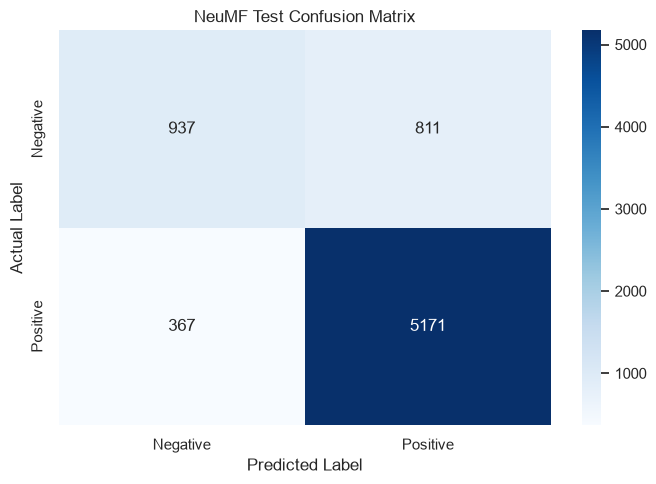

In [10]:
# Mengonversi probabilitas prediksi menjadi label biner dengan threshold 0.5.
testLabels = [
  int(probability >= 0.5)
  for probability in testPredictions
]

# Menghitung confusion matrix dari target aktual dan label prediksi.
matrix = confusion_matrix(
  testTargets,
  testLabels,
  labels=[0, 1],
)

# Membuat figure dan axes untuk visualisasi confusion matrix.
fig, ax = plt.subplots(figsize=(7, 5))

# Menampilkan confusion matrix dalam bentuk heatmap.
sns.heatmap(
  matrix,
  annot=True,
  fmt='d',
  cmap='Blues',
  xticklabels=['Negative', 'Positive'],
  yticklabels=['Negative', 'Positive'],
  ax=ax,
)

# Mengatur judul grafik dan label sumbu.
ax.set(
  title='NeuMF Test Confusion Matrix',
  xlabel='Predicted Label',
  ylabel='Actual Label',
)

# Menyesuaikan tata letak dan menampilkan grafik.
plt.tight_layout()
plt.show()